# MODUL PRAKTIKUM 6: KUSTOMISASI VISUALISASI MATPLOTLIB
**Mata Kuliah:** Visualisasi Data  
**Pertemuan Ke-:** 6 (enam)  
**Topik:** Kustomisasi Visualisasi (Label, Legenda, Subplot, Tema Warna)  
**Dataset:** Titanic Dataset (seaborn-data)  

### Identitas Mahasiswa
- **Nama Mahasiswa:** Gathan Hilabi
- **NIM:** 60324059
- **Kelas / Prodi:** S1 Informatika
- **Tanggal Praktikum:** 10 Oktober 2026

---

### 1. Menyiapkan Notebook dan Memuat Ulang Data Bersih
Memuat dataset Titanic dan menjalankan pipeline pembersihan data dari Pertemuan 3.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Memuat data Titanic langsung dari repository publik seaborn-data
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df_raw = pd.read_csv(url)

# Pipeline pembersihan data dari Pertemuan 3
df = df_raw.copy()
df["age"] = df["age"].fillna(df["age"].mean())
df = df.dropna(subset=["embarked"])
df = df.drop_duplicates()

print("Bentuk data bersih:", df.shape)
df.head()

Bentuk data bersih: (782, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### 2. Membuat Grafik Berkelompok (Grouped Bar) dengan Legenda
Membuat pivot table tingkat keselamatan per kelas dan jenis kelamin, lalu menampilkan grafik batang berkelompok dengan legenda.

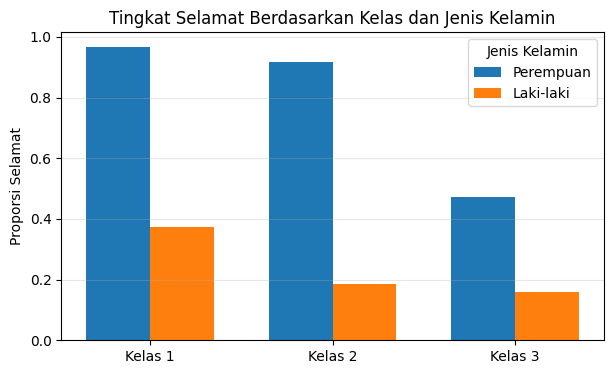

In [2]:
# Pivot table tingkat selamat per kelas dan jenis kelamin
pt = df.pivot_table(values="survived", index="pclass", columns="sex", aggfunc="mean")

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(pt.index))
width = 0.35

ax.bar(x - width/2, pt["female"], width, label="Perempuan")
ax.bar(x + width/2, pt["male"], width, label="Laki-laki")

ax.set_title("Tingkat Selamat Berdasarkan Kelas dan Jenis Kelamin")
ax.set_xticks(x)
ax.set_xticklabels([f"Kelas {c}" for c in pt.index])
ax.set_ylabel("Proporsi Selamat")
ax.legend(title="Jenis Kelamin")
ax.grid(axis="y", alpha=0.3)
plt.show()

### 3. Menata Grid dan Sumbu
Mencoba opsi penataan grid putus-putus, mengunci rentang sumbu Y, dan menyembunyikan spines.

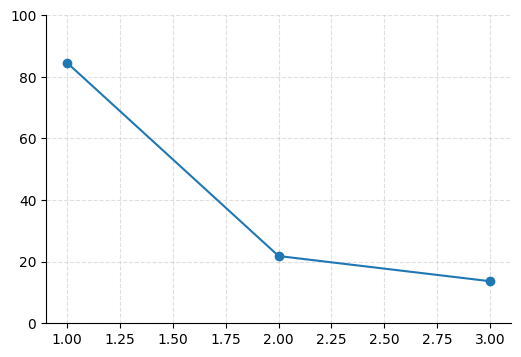

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
rata_fare = df.groupby("pclass")["fare"].mean()
ax.plot(rata_fare.index, rata_fare.values, marker="o")
ax.grid(True, linestyle="--", alpha=0.4)
ax.set_ylim(0, 100)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

### 4. Membuat Grid Subplot 2x2
Menyusun 4 grafik dalam grid 2 baris × 2 kolom menggunakan `plt.subplots(2, 2, ...)`.

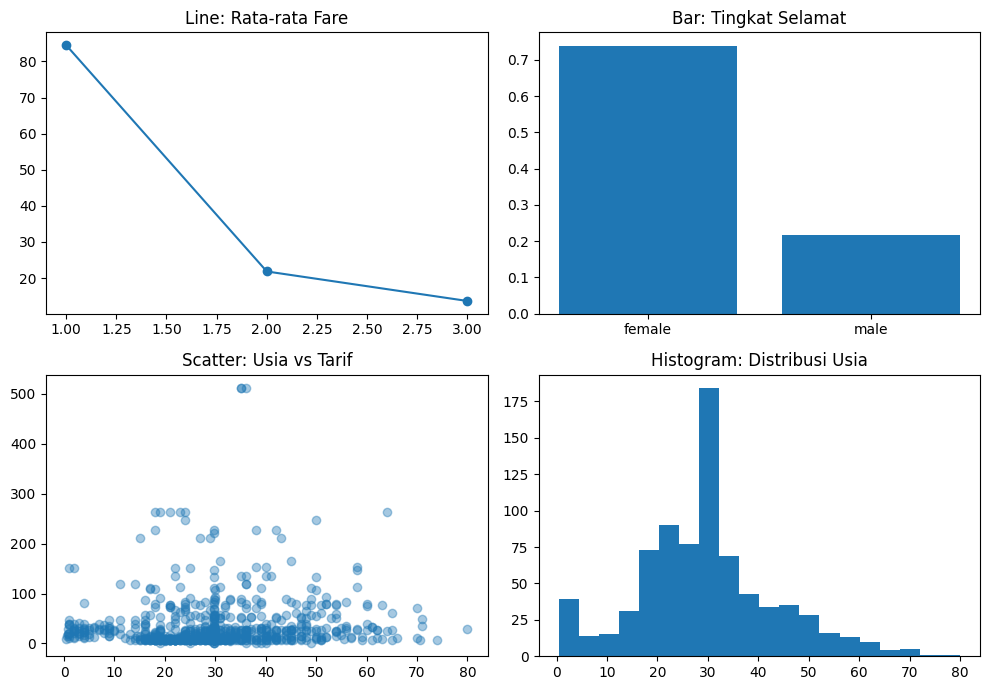

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
tingkat = df.groupby("sex")["survived"].mean()

axes[0,0].plot(rata_fare.index, rata_fare.values, marker="o")
axes[0,0].set_title("Line: Rata-rata Fare")

axes[0,1].bar(tingkat.index, tingkat.values)
axes[0,1].set_title("Bar: Tingkat Selamat")

axes[1,0].scatter(df["age"], df["fare"], alpha=0.4)
axes[1,0].set_title("Scatter: Usia vs Tarif")

axes[1,1].hist(df["age"], bins=20)
axes[1,1].set_title("Histogram: Distribusi Usia")

plt.tight_layout(); plt.show()